# Sobol SA — Ambulance Pooling Usefulness

Which uncertainties drive how much ambulance pooling helps or hurts T1 mortality?

Approach:
1. Pair each Saltelli row's stovepipe (amb=0) and pool (amb=1) results
2. Compute delta = mortality_pool − mortality_stovepipe
3. Feed deltas into SALib Sobol analyzer using the original Saltelli design order

In [24]:
import sys
from pathlib import Path
_root = Path(".").resolve()
while not (_root / "paths.py").exists():
    _root = _root.parent
sys.path.insert(0, str(_root))
import paths

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from SALib.analyze import sobol as sobol_analyze

# ── CONFIGURATION ────────────────────────────────────────────────────────────
RESULTS_PATH = _root / "data_cluster" / "20260605_145238_scenario_2btg_1ccp_each_ambulance_baseline" / "results.csv"
OUTCOME = "death_rate_T1_BCAS"
# ─────────────────────────────────────────────────────────────────────────────

df = pd.read_csv(RESULTS_PATH)
print(f"Loaded {len(df)} runs")
print(f"Policies: {df['ambulance_eligibility'].unique()}")

Loaded 12288 runs
Policies: [0 1]


In [25]:
# ── Split by policy, preserving Saltelli row order ───────────────────────────
UNCERTAINTIES = ["ccp_r1_same_bn_min", "ccp_r1_inter_bn_min", "bcas_rate", "waves_per_day", "wave_duration_min"]

base = df[df["ambulance_eligibility"] == 0].sort_values("scenario").reset_index(drop=True)
pool = df[df["ambulance_eligibility"] == 1].sort_values("scenario").reset_index(drop=True)

print(f"Stovepipe: {len(base)} rows")
print(f"Pool amb:  {len(pool)} rows")

# Verify same scenario order
assert (base["scenario"].values == pool["scenario"].values).all(), "Scenario order mismatch!"

delta = pool[OUTCOME].values - base[OUTCOME].values
print(f"\nDelta range: {delta.min():.4f} to {delta.max():.4f}")
print(f"Mean delta: {delta.mean():.4f}")
print(f"Pooling hurt in {(delta > 0).sum()} / {len(delta)} ({(delta > 0).mean():.1%}) scenarios")

Stovepipe: 6144 rows
Pool amb:  6144 rows

Delta range: -1.0000 to 0.5000
Mean delta: -0.4490
Pooling hurt in 10 / 6144 (0.2%) scenarios


In [26]:
# ── SALib problem definition ─────────────────────────────────────────────────
problem = {
    "num_vars": len(UNCERTAINTIES),
    "names": UNCERTAINTIES,
    "bounds": [
        [10, 20],     # ccp_r1_same_bn_min
        [15, 35],     # ccp_r1_inter_bn_min
        [0.01, 0.07], # bcas_rate
        [1, 6],       # waves_per_day
        [1, 60],      # wave_duration_min
    ],
}

N = len(base) // (2 * problem["num_vars"] + 2)
print(f"Inferred N = {N} (expected 512)")
print(f"Expected Saltelli rows: {N * (2 * problem['num_vars'] + 2)} = {N * (2 * problem['num_vars'] + 2)}")
print(f"Actual rows: {len(delta)}")

Inferred N = 512 (expected 512)
Expected Saltelli rows: 6144 = 6144
Actual rows: 6144


In [27]:
# ── Run Sobol analysis ───────────────────────────────────────────────────────
Si = sobol_analyze.analyze(problem, delta, calc_second_order=True, print_to_console=True)

                           ST   ST_conf
ccp_r1_same_bn_min   0.755942  0.099585
ccp_r1_inter_bn_min  0.054348  0.015151
bcas_rate            0.124397  0.029880
waves_per_day        0.255286  0.043149
wave_duration_min    0.688769  0.109648
                           S1   S1_conf
ccp_r1_same_bn_min   0.213002  0.098813
ccp_r1_inter_bn_min  0.006969  0.027403
bcas_rate            0.012326  0.042566
waves_per_day        0.059520  0.061635
wave_duration_min    0.011736  0.117486
                                                 S2   S2_conf
(ccp_r1_same_bn_min, ccp_r1_inter_bn_min)  0.010660  0.130077
(ccp_r1_same_bn_min, bcas_rate)            0.017563  0.132122
(ccp_r1_same_bn_min, waves_per_day)       -0.001354  0.134217
(ccp_r1_same_bn_min, wave_duration_min)    0.480074  0.201403
(ccp_r1_inter_bn_min, bcas_rate)          -0.000343  0.038217
(ccp_r1_inter_bn_min, waves_per_day)      -0.018268  0.038557
(ccp_r1_inter_bn_min, wave_duration_min)   0.003370  0.040037
(bcas_rate, waves_per_da

## First-Order and Total-Order Indices

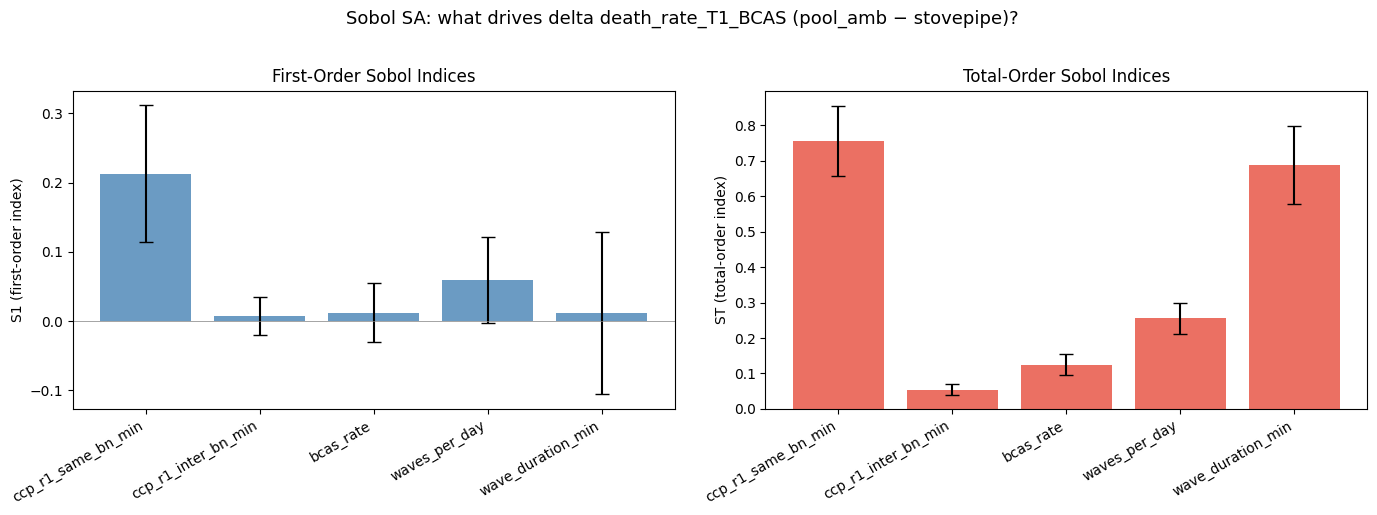

                        S1  S1_conf     ST  ST_conf
ccp_r1_same_bn_min  0.2130   0.0988 0.7559   0.0996
ccp_r1_inter_bn_min 0.0070   0.0274 0.0543   0.0152
bcas_rate           0.0123   0.0426 0.1244   0.0299
waves_per_day       0.0595   0.0616 0.2553   0.0431
wave_duration_min   0.0117   0.1175 0.6888   0.1096


In [28]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

x_pos = np.arange(len(UNCERTAINTIES))

# S1
axes[0].bar(x_pos, Si["S1"], yerr=Si["S1_conf"], capsize=5, color="steelblue", alpha=0.8)
axes[0].set_xticks(x_pos)
axes[0].set_xticklabels(UNCERTAINTIES, rotation=30, ha="right")
axes[0].set_ylabel("S1 (first-order index)")
axes[0].set_title("First-Order Sobol Indices")
axes[0].axhline(0, color="grey", linewidth=0.5)

# ST
axes[1].bar(x_pos, Si["ST"], yerr=Si["ST_conf"], capsize=5, color="#e74c3c", alpha=0.8)
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels(UNCERTAINTIES, rotation=30, ha="right")
axes[1].set_ylabel("ST (total-order index)")
axes[1].set_title("Total-Order Sobol Indices")
axes[1].axhline(0, color="grey", linewidth=0.5)

fig.suptitle(f"Sobol SA: what drives delta {OUTCOME} (pool_amb − stovepipe)?", fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

# Summary table
summary = pd.DataFrame({"S1": Si["S1"], "S1_conf": Si["S1_conf"],
                         "ST": Si["ST"], "ST_conf": Si["ST_conf"]},
                        index=UNCERTAINTIES)
print(summary.to_string(float_format="%.4f"))

## Second-Order Indices (Pairwise Interactions)

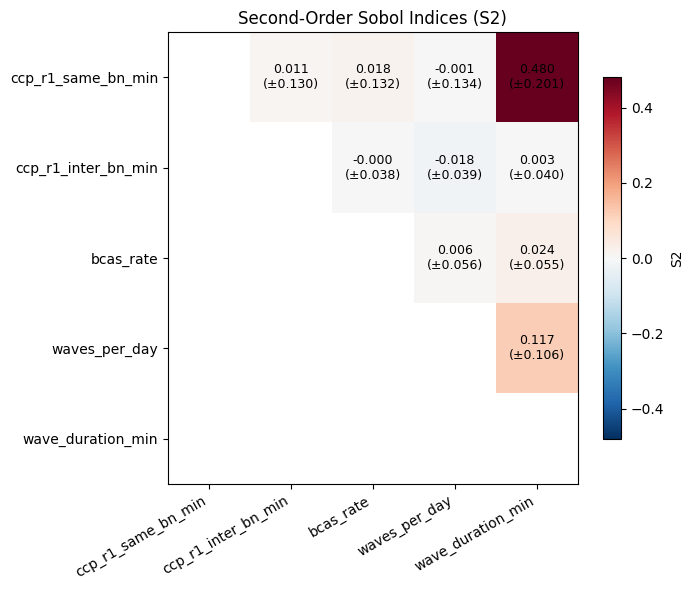


S2 matrix:
                     ccp_r1_same_bn_min  ccp_r1_inter_bn_min  bcas_rate  waves_per_day  wave_duration_min
ccp_r1_same_bn_min                  NaN               0.0107     0.0176        -0.0014             0.4801
ccp_r1_inter_bn_min                 NaN                  NaN    -0.0003        -0.0183             0.0034
bcas_rate                           NaN                  NaN        NaN         0.0058             0.0238
waves_per_day                       NaN                  NaN        NaN            NaN             0.1172
wave_duration_min                   NaN                  NaN        NaN            NaN                NaN


In [29]:
S2 = pd.DataFrame(Si["S2"], index=UNCERTAINTIES, columns=UNCERTAINTIES)
S2_conf = pd.DataFrame(Si["S2_conf"], index=UNCERTAINTIES, columns=UNCERTAINTIES)

# Heatmap — SALib stores S2 in the upper triangle, diagonal is NaN
fig, ax = plt.subplots(figsize=(7, 6))
mask = np.tril(np.ones_like(S2, dtype=bool), k=0)  # hide diagonal + lower triangle
s2_masked = S2.where(~mask)

vabs = max(0.01, np.nanmax(np.abs(s2_masked.values.astype(float))))
im = ax.imshow(s2_masked.values.astype(float), cmap="RdBu_r", vmin=-vabs, vmax=vabs, aspect="auto")
ax.set_xticks(range(len(UNCERTAINTIES)))
ax.set_xticklabels(UNCERTAINTIES, rotation=30, ha="right")
ax.set_yticks(range(len(UNCERTAINTIES)))
ax.set_yticklabels(UNCERTAINTIES)
ax.set_title("Second-Order Sobol Indices (S2)")

for i in range(len(UNCERTAINTIES)):
    for j in range(len(UNCERTAINTIES)):
        if not mask[i, j]:
            v = S2.iloc[i, j]
            c = S2_conf.iloc[i, j]
            if not np.isnan(v):
                ax.text(j, i, f"{v:.3f}\n(±{c:.3f})", ha="center", va="center", fontsize=9)

plt.colorbar(im, ax=ax, shrink=0.8, label="S2")
plt.tight_layout()
plt.show()

print("\nS2 matrix:")
print(S2.to_string(float_format="%.4f"))

## Sobol Comparison: Stovepipe (amb=0) vs Ambulance Pooling (amb=1)

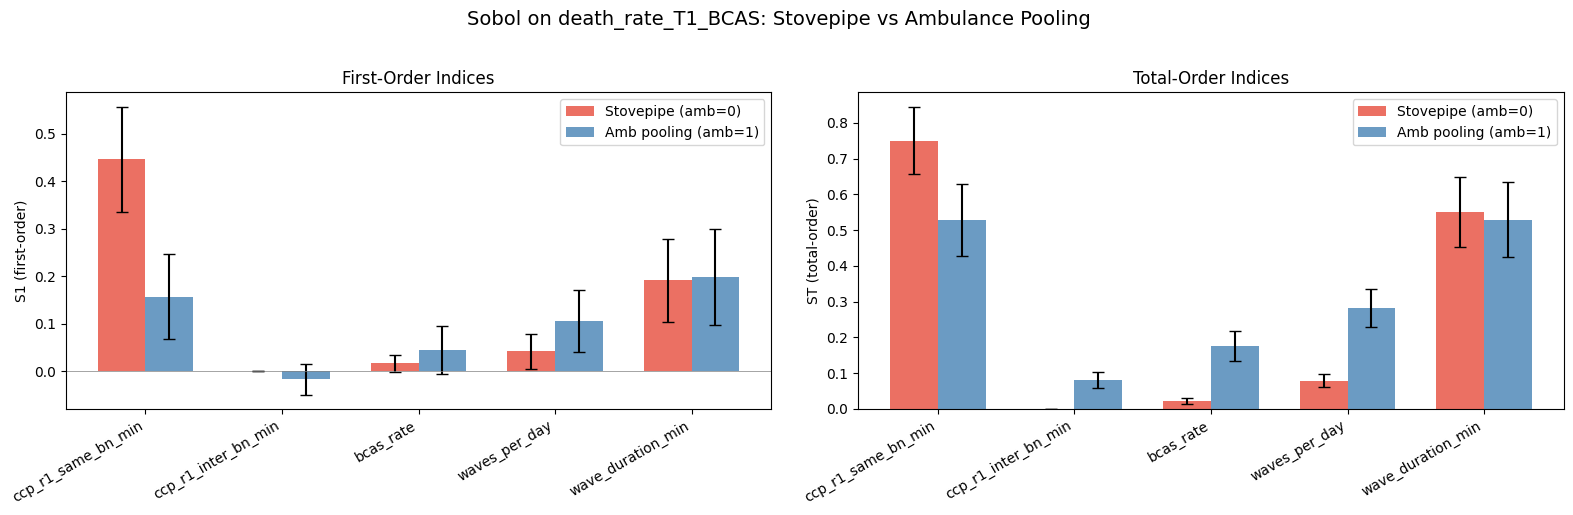

=== Stovepipe (amb=0) ===
                        S1  S1_conf     ST  ST_conf
ccp_r1_same_bn_min  0.4455   0.1110 0.7498   0.0930
ccp_r1_inter_bn_min 0.0000   0.0000 0.0000   0.0000
bcas_rate           0.0160   0.0186 0.0218   0.0091
waves_per_day       0.0419   0.0366 0.0793   0.0192
wave_duration_min   0.1909   0.0868 0.5503   0.0974

=== Ambulance Pooling (amb=1) ===
                         S1  S1_conf     ST  ST_conf
ccp_r1_same_bn_min   0.1569   0.0896 0.5272   0.1006
ccp_r1_inter_bn_min -0.0168   0.0325 0.0816   0.0226
bcas_rate            0.0446   0.0506 0.1769   0.0419
waves_per_day        0.1061   0.0653 0.2810   0.0533
wave_duration_min    0.1982   0.1012 0.5292   0.1039


In [32]:
# ── Run Sobol for both policies ───────────────────────────────────────────────
Si_pool = sobol_analyze.analyze(problem, pool[OUTCOME].values, calc_second_order=True)
Si_base = sobol_analyze.analyze(problem, base[OUTCOME].values, calc_second_order=True)

# ── Side-by-side comparison: S1 ──────────────────────────────────────────────
x_pos = np.arange(len(UNCERTAINTIES))
w = 0.35

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# S1
axes[0].bar(x_pos - w/2, Si_base["S1"], w, yerr=Si_base["S1_conf"], capsize=4,
            color="#e74c3c", alpha=0.8, label="Stovepipe (amb=0)")
axes[0].bar(x_pos + w/2, Si_pool["S1"], w, yerr=Si_pool["S1_conf"], capsize=4,
            color="steelblue", alpha=0.8, label="Amb pooling (amb=1)")
axes[0].set_xticks(x_pos)
axes[0].set_xticklabels(UNCERTAINTIES, rotation=30, ha="right")
axes[0].set_ylabel("S1 (first-order)")
axes[0].set_title("First-Order Indices")
axes[0].axhline(0, color="grey", linewidth=0.5)
axes[0].legend()

# ST
axes[1].bar(x_pos - w/2, Si_base["ST"], w, yerr=Si_base["ST_conf"], capsize=4,
            color="#e74c3c", alpha=0.8, label="Stovepipe (amb=0)")
axes[1].bar(x_pos + w/2, Si_pool["ST"], w, yerr=Si_pool["ST_conf"], capsize=4,
            color="steelblue", alpha=0.8, label="Amb pooling (amb=1)")
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels(UNCERTAINTIES, rotation=30, ha="right")
axes[1].set_ylabel("ST (total-order)")
axes[1].set_title("Total-Order Indices")
axes[1].axhline(0, color="grey", linewidth=0.5)
axes[1].legend()

fig.suptitle(f"Sobol on {OUTCOME}: Stovepipe vs Ambulance Pooling", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

# ── Summary tables ───────────────────────────────────────────────────────────
print("=== Stovepipe (amb=0) ===")
print(pd.DataFrame({"S1": Si_base["S1"], "S1_conf": Si_base["S1_conf"],
                     "ST": Si_base["ST"], "ST_conf": Si_base["ST_conf"]},
                    index=UNCERTAINTIES).to_string(float_format="%.4f"))
print("\n=== Ambulance Pooling (amb=1) ===")
print(pd.DataFrame({"S1": Si_pool["S1"], "S1_conf": Si_pool["S1_conf"],
                     "ST": Si_pool["ST"], "ST_conf": Si_pool["ST_conf"]},
                    index=UNCERTAINTIES).to_string(float_format="%.4f"))

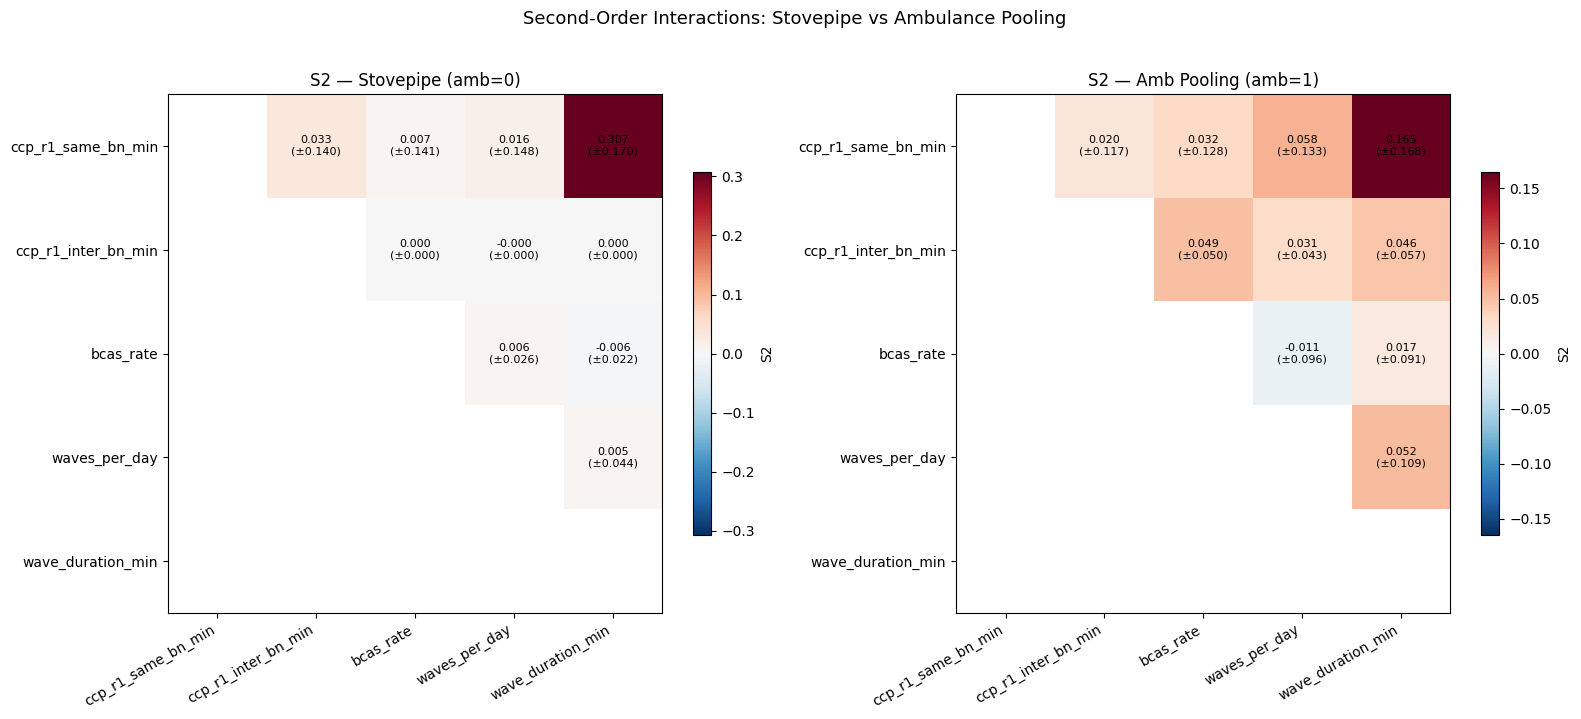

In [31]:
# ── S2 heatmaps side by side ─────────────────────────────────────────────────
S2_base = pd.DataFrame(Si_base["S2"], index=UNCERTAINTIES, columns=UNCERTAINTIES)
S2_base_conf = pd.DataFrame(Si_base["S2_conf"], index=UNCERTAINTIES, columns=UNCERTAINTIES)
S2_pool = pd.DataFrame(Si_pool["S2"], index=UNCERTAINTIES, columns=UNCERTAINTIES)
S2_pool_conf = pd.DataFrame(Si_pool["S2_conf"], index=UNCERTAINTIES, columns=UNCERTAINTIES)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
mask = np.tril(np.ones((len(UNCERTAINTIES), len(UNCERTAINTIES)), dtype=bool), k=0)

for ax, S2_df, S2_cf, title in [
    (axes[0], S2_base, S2_base_conf, "S2 — Stovepipe (amb=0)"),
    (axes[1], S2_pool, S2_pool_conf, "S2 — Amb Pooling (amb=1)"),
]:
    s2_masked = S2_df.where(~mask)
    vabs = max(0.01, np.nanmax(np.abs(s2_masked.values.astype(float))))
    im = ax.imshow(s2_masked.values.astype(float), cmap="RdBu_r", vmin=-vabs, vmax=vabs, aspect="auto")
    ax.set_xticks(range(len(UNCERTAINTIES)))
    ax.set_xticklabels(UNCERTAINTIES, rotation=30, ha="right")
    ax.set_yticks(range(len(UNCERTAINTIES)))
    ax.set_yticklabels(UNCERTAINTIES)
    ax.set_title(title)
    for i in range(len(UNCERTAINTIES)):
        for j in range(len(UNCERTAINTIES)):
            if not mask[i, j]:
                v = S2_df.iloc[i, j]
                c = S2_cf.iloc[i, j]
                if not np.isnan(v):
                    ax.text(j, i, f"{v:.3f}\n(±{c:.3f})", ha="center", va="center", fontsize=8)
    plt.colorbar(im, ax=ax, shrink=0.7, label="S2")

plt.suptitle("Second-Order Interactions: Stovepipe vs Ambulance Pooling", fontsize=13, y=1.02)
plt.tight_layout()
plt.show()